(P:python)=
# Installer et utiliser Python

Python est un langage de haut niveau moderne et très répandu dans l'industrie et les disciplines scientifiques.
Cette page décrit comment :
* installer Python et Jupyter avec la distribution Anaconda,
* écrire des _notebooks_ avec Jupyter Lab,
* utiliser des modules additionnels et commencer à programmer.

## Installation

Anaconda est une distribution Python spécialisée notamment dans la science des données et l'apprentissage machine.
Pour un usage individuel, elle est gratuite et suffisante pour effectuer les TP de traitement du signal.
[Téléchargez](https://www.anaconda.com/download) et installer Anaconda si Python n'est pas déjà présent sur votre ordinateur.

En plus de regrouper le cœur de Python et les modules scientifiques principaux,
Anaconda propose un environnement de développement pour écrire des programmes et des notebooks appelé
[JupyterLab](https://jupyterlab.readthedocs.io/).

La {numref}`figure {number} <F:python:jupyterlab>` montre l'interface de Jupyter Lab :
elle est suffisamment intuitive pour se débrouiller sans aide, mais vous pouvez toujours consulter
[cette page](https://jupyterlab.readthedocs.io/en/latest/user/interface.html) pour en savoir plus.

```{figure} https://jupyterlab.readthedocs.io/en/latest/_images/interface-jupyterlab.png
:name: F:python:jupyterlab

Jupyter Lab.
```

Normalement, Jupyter Lab est inclus dans l'installation d'Anaconda.
Mais si ce n'est pas le cas, vous trouverez les instructions pour installer Jupyter Lab [ici](https://jupyter.org/install.html).

Pour ouvrir Jupyter Lab, tapez dans un terminal `jupyter lab` ou `jupyter-lab`.

(P:python:notebook)=
## Notebooks Python

Après avoir installé Anaconda, vous êtes prêt à écrire et exécuter des notebooks Python !
Un [notebook](https://jupyterlab.readthedocs.io/en/latest/user/notebook.html) est un fichier contenant du code,
mais également les résultats produits par ce code (comme des valeurs numériques ou des images) et du texte qui accompagnera le code.
Un notebook est divisé en _cellules_ qui peuvent être de deux types : « code » ou « markdown ».
En appuyant sur {kbd}`Ctrl` + {kbd}`Entrée` dans une cellule, le code de celle-ci (et uniquement de celle-ci) est exécuté.
Si à la place vous appuyez sur {kbd}`Shift` + {kbd}`Entrée`, alors le code de la cellule courante est exécuté et le curseur passe sur la cellule suivante.


### Cellules de code

Les cellules contiennent par défaut du code Python (_input_) et le résultat (_output_).

Par exemple le code (_input_) suivant :

```python
a = 21
b = 42
c = a + b
print("La valeur est " + str(c))
```

produit le résultat (_output_) :
  
    La valeur est 63
    
  
### Cellules Markdown

Il est possible de changer une cellule de « code » en cellule « markdown » en sélectionnant _Markdown_ dans la liste déroulante de la barre d'outils.
Le [Markdown](https://en.wikipedia.org/wiki/Markdown) est aussi un langage informatique, mais il sert à mettre en forme du texte
(par exemple en écrivant des titres, des listes, des équations...).
Cela peut être utile pour ajouter des notes et commenter votre code et ses résultats.

Ainsi :

```code
  ### Définition

  la _sinusoïde_ a pour expression :
  
  $$
    x(t) = A \sin(2 \pi f t + \varphi)
  $$
  
  où :
  * $A$ est l'amplitude
  * $f$ est la fréquence
  * $\varphi$ est le déphasage
```

produit :

::::{grid} 1

:::{card}

<html><h3>Définition</h3></html>

la _sinusoïde_ a pour expression :

$$
  x(t) = A \sin(2 \pi f t + \varphi)
$$

où :
* $A$ est l'amplitude
* $f$ est la fréquence
* $\varphi$ est le déphasage

:::
::::

Vous trouverez le résumé de la syntaxe Markdown sur [cette page](https://en.wikipedia.org/wiki/Markdown#Examples).

(P:python:python)=
## Écrire un programme Python

Le cœur du langage Python ne dispose pas de toutes les fonctions utiles pour la programmation scientifique, et en particulier le traitement du signal.
Il est donc nécessaire d'importer des modules dans votre code (normalement, ces modules sont installés avec Anaconda).
En général, nous n'utiliserons que deux modules :
* [numpy](https://numpy.org/), qui fournit des fonctions générales pour la programmation scientifique,
* [matplotlib](https://matplotlib.org/), pour afficher les signaux.

Les modules Python sont importés dans votre code en utilisant l'instruction `import`.

Par exemple, le code suivant affiche la sinusoïde $\sin(2\pi f n)$ de fréquence $f=0,3$ Hz :

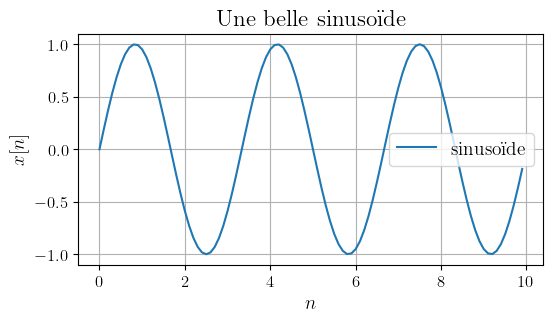

In [39]:
#| label: toto

# Une ligne qui commence par le symbole # est un commentaire
# et n'est donc pas exécutée

# Import du module 'numpy' et renommage en 'np' car c'est
# plus court à écrire
import numpy as np

# Import du sous-module 'pyplot' du module 'matplotlib',
# et renommage en 'plt'
import matplotlib.pyplot as plt

# Abscisses sur lesquelles sera calculée la sinusoïde :
# un point tous les 0,1 s entre 0 et 10 s
n = np.arange(0, 10, 0.1)

# Fréquence de la sinusoïde
f = 0.3

# Sinusoïde : c'est tout simple, il suffit d'écrire
# l'expression mathématique 😎
x = np.sin(2*np.pi*f*n)

# Création d'une figure, dont on définit la taille
plt.figure(figsize=(6,3))

# Affichage de la sinusoïde (dans la figure créée)
plt.plot(n, x, label="sinusoïde")

# Légende
plt.legend()

# Légende des axes et titre
plt.xlabel("$n$")
plt.ylabel("$x[n]$")
plt.title("Une belle sinusoïde")

# Affichage (pas toujours nécessaire, mais parfois indispensable)
plt.show()

**####################################################**

**Cellules cachées**

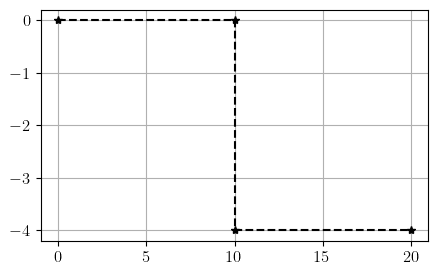

In [40]:
#| label: C:filtrage:gabarit

# Abscisses des 4 points de la ligne brisée
x = [0, 10, 10, 20]

# Ordonnées des 4 points de la ligne brisée
y = [0, 0, -4, -4]

# Affichage
plt.figure(figsize=(5,3))
plt.plot(x, y, color='k', linestyle='--', marker='*')
plt.show()

In [41]:
from scipy.io.wavfile import read
from IPython.display import Audio
plt.style.use('../src/signal.mplstyle')

In [42]:
def display(x, fe):
    N = len(x)
    t = np.arange(N) / fe
    plt.figure(figsize=(10,2), facecolor="#00000000")
    plt.plot(t,x)
    plt.xlim([0, 1e-2])
    plt.ylim([-.7, .7])
    plt.xlabel("$t$ (s)")
    plt.show()

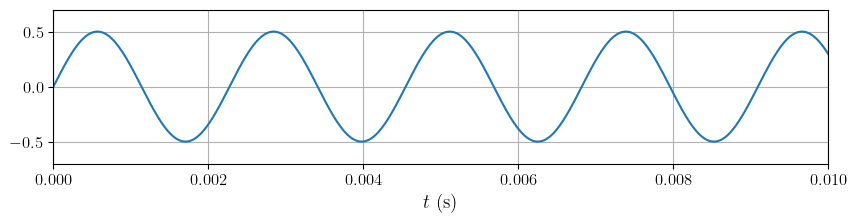

In [43]:
#| label: C:ssp:signal-x
fe, x = read("../ssp/figs/x.wav")
display(x, fe)
Audio(x, rate=fe)

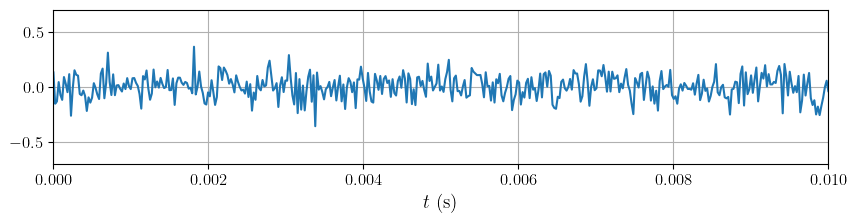

In [44]:
#| label: C:ssp:signal-b
fe, b = read("../ssp/figs/b.wav")
display(b, fe)
Audio(b, rate=fe)

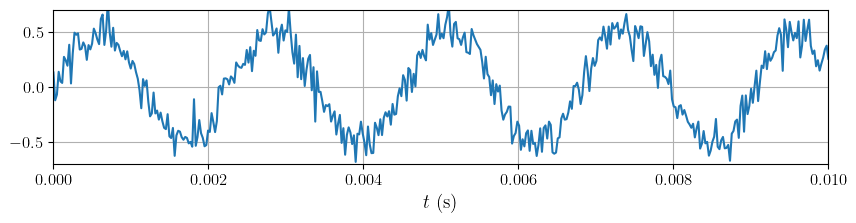

In [45]:
#| label: C:ssp:signal-y
fe, y = read("../ssp/figs/y.wav")
display(y, fe)
Audio(y, rate=fe)